# 02B · Nguyễn Mạnh Hà — Q3 & Q4
**Bản nháp thực nghiệm có AI hỗ trợ.** Không xác nhận Hà tự thiết kế/thực hiện
hay đã đủ điều kiện nộp. Các số liệu được tính từ CSV UCI thật, không điền giả.
Xem `../LLM_USAGE.md`, `../docs/ha_analysis_protocol.md` và
`../docs/ha_handoff.md`. Hà cần tự thực hiện, hiểu và diễn giải theo quy định.

Notebook chạy độc lập từ kernel mới. Raw bất biến; mọi bảng/hình mang tiền tố
`ha_`. Chỉ làm Q3/Q4, không fit mô hình hoặc thay phần của Dương/Lý.

In [1]:
import hashlib
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/coupon_project").is_dir(), "Start in repo root or notebooks/"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coupon_project.analysis import (
    COUPON_FREQUENCY,
    COUPONS,
    DESTINATIONS,
    FREQUENCIES,
    MIN_N,
    N_BOOT,
    PASSENGERS,
    SEED,
    audit_row,
    contrasts,
    heatmap_rates,
    matched_frequency,
    rate_table,
    save_figure,
    save_table,
    standardized_contrast,
)
from coupon_project.data_io import load_raw_data
from coupon_project.quality import missing_table, target_is_binary

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)

raw_path = ROOT / "data/raw/in-vehicle-coupon-recommendation.csv"
df = load_raw_data(raw_path)
assert target_is_binary(df)

raw_sha = hashlib.sha256(raw_path.read_bytes()).hexdigest()
audit = []

print(f"Raw: {df.shape[0]:,} rows x {df.shape[1]} columns; SHA-256: {raw_sha}")
print(f"MIN_N={MIN_N}; bootstrap={N_BOOT:,}; seed={SEED}; rates in [0,1], differences in pp")

Raw: 12,684 rows x 26 columns; SHA-256: d47897367f5a12a31dece0f4e42d7bd9da76d7016b568da511b50335d08dcb43
MIN_N=30; bootstrap=10,000; seed=17104; rates in [0,1], differences in pp


## 1. Quy ước chốt trước khi đọc kết quả
- `rate=mean(Y)`, kèm n và accepted; Wilson CI 95% cho tỷ lệ.
- Chênh lệch A−B tính bằng **điểm phần trăm**, bootstrap 10.000 lượt/seed 17104.
- `MIN_N=30`: đánh dấu nhóm nhỏ, ô trống không gán 0%. Không chọn so sánh theo p-value.
- CI giả định các dòng độc lập; thiếu participant ID, có thể quá hẹp, chưa hiệu chỉnh
  nhiều so sánh. Chỉ mô tả **mối liên hệ**, không suy luận nhân quả.
- Giữ duplicate ở chính; không dropna mọi cột. Q3 thử loại duplicate như sensitivity.
- Hai Q4 contrasts chốt trước: Friend(s)−Alone và Partner−Alone.

## Q3 — Thói quen và coupon phù hợp (D3, D4, D5, D6)
**Câu hỏi:** Trong cùng loại coupon, tần suất ghé địa điểm tương ứng liên hệ
thế nào với ý định chấp nhận?

**Motivation:** Người thiết kế ưu đãi có thể cân nhắc dùng thói quen tự báo cáo
để thử nghiệm cách cá nhân hóa. Kết quả khảo sát chưa chứng minh hiệu quả triển khai.

**Cột:** coupon, Bar, CoffeeHouse, CarryAway, RestaurantLessThan20,
Restaurant20To50, Y. D3 mapping đúng địa điểm; D4 so sánh riêng từng coupon;
D5 CI và điểm phần trăm; D6 đổi ngưỡng và xử lý NaN.

In [2]:
print("CSV coupon labels:", df["coupon"].unique().tolist())

mapping = pd.DataFrame(COUPON_FREQUENCY.items(), columns=["coupon", "habit_column"])
display(mapping)
save_table(mapping, ROOT, "q3_mapping")

q3 = df.copy()
q3["matched_frequency"] = matched_frequency(q3)
q3["frequent_user"] = pd.Series(pd.NA, index=q3.index, dtype="Int64")

observed = q3["matched_frequency"].notna()
q3.loc[observed, "frequent_user"] = q3.loc[observed, "matched_frequency"].isin(["1~3", "4~8", "gt8"]).astype(int)

audit.append(
    audit_row(
        "Q3 mapping and frequent_user",
        len(df),
        len(q3),
        "Add variables, no row removal; NaN remains unknown",
    )
)

habit_cols = list(COUPON_FREQUENCY.values()) + ["matched_frequency"]
display(missing_table(q3[habit_cols]))

q3["frequency_display"] = q3["matched_frequency"].fillna("Unknown")
frequency_rates = rate_table(q3, ["coupon", "frequency_display"])
assert frequency_rates["n"].sum() == len(q3)

display(frequency_rates)
save_table(frequency_rates, ROOT, "q3_frequency_rates")

CSV coupon labels: ['Restaurant(<20)', 'Coffee House', 'Carry out & Take away', 'Bar', 'Restaurant(20-50)']


,coupon,habit_column
0,Bar,Bar
1,Coffee House,CoffeeHouse
2,Carry out & Take away,CarryAway
3,Restaurant(<20),RestaurantLessThan20
4,Restaurant(20-50),Restaurant20To50


,missing_count,missing_pct
CoffeeHouse,217,1.71
Restaurant20To50,189,1.49
matched_frequency,164,1.29
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Bar,107,0.84


,coupon,frequency_display,n,accepted,rate,ci_low,ci_high,small_n
0,Bar,1~3,397,257,0.647355,0.599148,0.692738,False
1,Bar,4~8,150,117,0.780000,0.707177,0.838840,False
2,Bar,Unknown,21,8,0.380952,0.207510,0.591213,True
3,Bar,gt8,49,36,0.734694,0.597377,0.837887,False
4,Bar,less1,570,253,0.443860,0.403583,0.484888,False
5,Bar,never,830,156,0.187952,0.162834,0.215945,False
6,Carry out & Take away,1~3,864,636,0.736111,0.705724,0.764408,False
7,Carry out & Take away,4~8,820,618,0.753659,0.723029,0.781922,False
8,Carry out & Take away,Unknown,22,19,0.863636,0.666650,0.952510,True
9,Carry out & Take away,gt8,302,223,0.738411,0.686069,0.784763,False


WindowsPath('C:/Users/MY MSI/Desktop/Môn học/Chuyên ngành/Data Science Programming/Project/reports/tables/ha_q3_frequency_rates.csv')

### Q3 phương pháp và robustness
Chính: frequent = `1~3/4~8/gt8`, infrequent = `never/less1`; chỉ loại khỏi
contrast dòng thiếu matched_frequency, bảng mô tả vẫn giữ Unknown.

Sensitivity 2×2: ngưỡng trên hoặc `4~8/gt8`; complete-case hoặc mode của
matched_frequency trong cùng coupon (không dùng Y). Mode giữ toàn bộ dòng,
nhưng không loại trừ bias thiếu dữ liệu. Thêm một phép thử không trùng hoàn toàn.

In [3]:
variants = []
thresholds = {
    "at_least_1": ["1~3", "4~8", "gt8"],
    "at_least_4": ["4~8", "gt8"],
}

for threshold, frequent_levels in thresholds.items():
    for missing_method in ["complete_case", "within_coupon_mode"]:
        work = q3.copy()

        if missing_method == "complete_case":
            work = work.loc[work["matched_frequency"].notna()].copy()
            reason = "Exclude only missing matched habit, not all missing raw fields"
            n_imputed = 0
        else:
            modes = work.groupby("coupon")["matched_frequency"].transform(
                lambda series: series.mode().iloc[0] if not series.mode().empty else pd.NA
            )
            work["matched_frequency"] = work["matched_frequency"].fillna(modes)
            assert work["matched_frequency"].notna().all()
            reason = "Descriptive sensitivity only; fill matched habit by coupon mode without Y"

        audit.append(audit_row(f"Q3 {threshold} / {missing_method}", len(q3), len(work), reason))
        work["frequent"] = work["matched_frequency"].isin(frequent_levels).astype(int)

        result = contrasts(work, ["coupon"], "frequent", 1, 0, key=("q3", threshold, missing_method))
        result["threshold"] = threshold
        result["missing_method"] = missing_method

        if missing_method == "within_coupon_mode":
            imputed_counts = q3.loc[q3["matched_frequency"].isna()].groupby("coupon").size()
            result["n_imputed"] = imputed_counts.reindex(result["coupon"], fill_value=0).to_numpy()
        else:
            result["n_imputed"] = 0

        variants.append(result)

sensitivity = pd.concat(variants, ignore_index=True)
display(sensitivity)
save_table(sensitivity, ROOT, "q3_sensitivity")

primary = sensitivity.loc[
    (sensitivity["threshold"] == "at_least_1")
    & (sensitivity["missing_method"] == "complete_case")
].copy()
display(primary)
save_table(primary, ROOT, "q3_primary_contrasts")

dedup = df.drop_duplicates().copy()
audit.append(audit_row("Q3 dedup sensitivity", len(df), len(dedup), "Sensitivity only; not claiming duplicate survey responses are errors"))

dedup["matched_frequency"] = matched_frequency(dedup)
n_before = len(dedup)
dedup = dedup.loc[dedup["matched_frequency"].notna()].copy()
audit.append(audit_row("Q3 dedup matched complete cases", n_before, len(dedup), "Exclude missing matched habit only"))

dedup["frequent"] = dedup["matched_frequency"].isin(thresholds["at_least_1"]).astype(int)
dedup_result = contrasts(dedup, ["coupon"], "frequent", 1, 0, key="q3_dedup")
display(dedup_result)
save_table(dedup_result, ROOT, "q3_dedup_contrasts")

,coupon,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status,threshold,missing_method,n_imputed
0,Bar,1,0,596,1400,410,409,0.687919,0.292143,False,39.577661,35.088998,44.109348,ok,at_least_1,complete_case,0
1,Carry out & Take away,1,0,1986,385,1477,264,0.743706,0.685714,False,5.799166,0.829642,10.869594,ok,at_least_1,complete_case,0
2,Coffee House,1,0,1922,2002,1269,693,0.660250,0.346154,False,31.409589,28.371005,34.358772,ok,at_least_1,complete_case,0
3,Restaurant(20-50),1,0,506,964,281,370,0.555336,0.383817,False,17.151854,11.756597,22.576499,ok,at_least_1,complete_case,0
4,Restaurant(<20),1,0,2245,514,1606,340,0.715367,0.661479,False,5.388888,0.906873,9.981143,ok,at_least_1,complete_case,0
5,Bar,1,0,596,1421,410,417,0.687919,0.293455,False,39.446415,35.002527,43.765852,ok,at_least_1,within_coupon_mode,21
6,Carry out & Take away,1,0,2008,385,1496,264,0.745020,0.685714,False,5.930563,0.928009,10.986874,ok,at_least_1,within_coupon_mode,22
7,Coffee House,1,0,1922,2074,1269,726,0.660250,0.350048,False,31.020152,28.058549,33.912043,ok,at_least_1,within_coupon_mode,72
8,Restaurant(20-50),1,0,506,986,281,377,0.555336,0.382353,False,17.298303,12.042909,22.611472,ok,at_least_1,within_coupon_mode,22
9,Restaurant(<20),1,0,2272,514,1630,340,0.717430,0.661479,False,5.595098,1.066738,10.058507,ok,at_least_1,within_coupon_mode,27


,coupon,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status,threshold,missing_method,n_imputed
0,Bar,1,0,596,1400,410,409,0.687919,0.292143,False,39.577661,35.088998,44.109348,ok,at_least_1,complete_case,0
1,Carry out & Take away,1,0,1986,385,1477,264,0.743706,0.685714,False,5.799166,0.829642,10.869594,ok,at_least_1,complete_case,0
2,Coffee House,1,0,1922,2002,1269,693,0.660250,0.346154,False,31.409589,28.371005,34.358772,ok,at_least_1,complete_case,0
3,Restaurant(20-50),1,0,506,964,281,370,0.555336,0.383817,False,17.151854,11.756597,22.576499,ok,at_least_1,complete_case,0
4,Restaurant(<20),1,0,2245,514,1606,340,0.715367,0.661479,False,5.388888,0.906873,9.981143,ok,at_least_1,complete_case,0


,coupon,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status
0,Bar,1,0,596,1393,410,406,0.687919,0.291457,False,39.646218,35.213658,43.961472,ok
1,Carry out & Take away,1,0,1946,377,1445,257,0.742549,0.681698,False,6.085121,1.018852,11.219369,ok
2,Coffee House,1,0,1918,1999,1266,690,0.660063,0.345173,False,31.488998,28.493104,34.441866,ok
3,Restaurant(20-50),1,0,504,962,280,370,0.555556,0.384615,False,17.094017,11.698924,22.442085,ok
4,Restaurant(<20),1,0,2240,512,1604,339,0.716071,0.662109,False,5.396205,0.870257,10.028041,ok


WindowsPath('C:/Users/MY MSI/Desktop/Môn học/Chuyên ngành/Data Science Programming/Project/reports/tables/ha_q3_dedup_contrasts.csv')

### Q3 biểu đồ (≥2)
Các cấp tần suất có thứ tự; Unknown đứng riêng. Cột có n và Wilson CI;
dấu * nghĩa là n<30, không xếp hạng chắc chắn. Hình hai ghi n ngay mỗi ô.

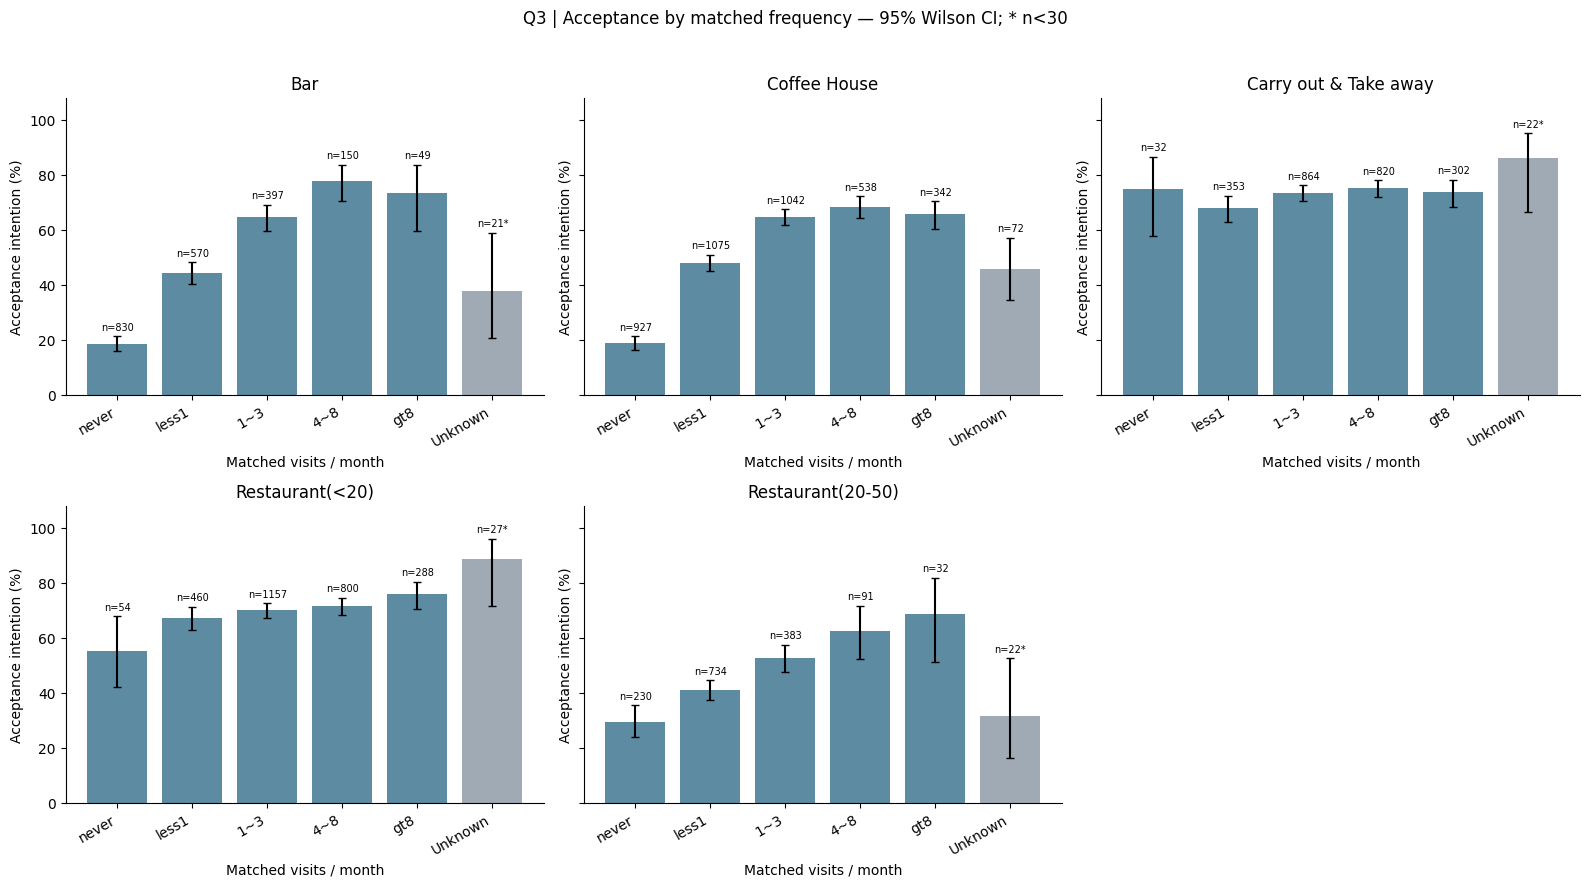

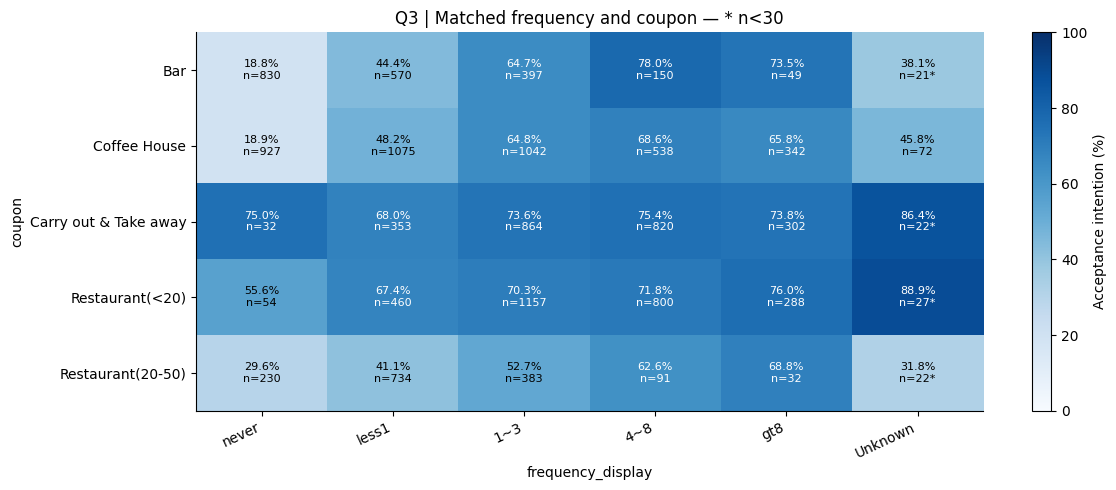

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
freq_order = FREQUENCIES + ["Unknown"]

for ax, coupon in zip(axes.flat, COUPONS):
    table = (
        frequency_rates.loc[frequency_rates["coupon"].eq(coupon)]
        .set_index("frequency_display")
        .reindex(freq_order)
    )
    for i, level in enumerate(freq_order):
        row = table.loc[level]
        if pd.isna(row["n"]):
            ax.text(i, 3, "n=0", ha="center", fontsize=7)
            continue

        color = "#8795a1" if level == "Unknown" else "#346e8b"
        yerr = np.array([[row["rate"] - row["ci_low"]], [row["ci_high"] - row["rate"]]]) * 100
        ax.bar(i, row["rate"] * 100, color=color, alpha=0.8)
        ax.errorbar(i, row["rate"] * 100, yerr=yerr, fmt="none", color="black", capsize=3)

        star = "*" if row["n"] < MIN_N else ""
        label_y = min(101, row["ci_high"] * 100 + 2)
        ax.text(i, label_y, f"n={int(row['n'])}{star}", ha="center", fontsize=7)

    ax.set(title=coupon, xlabel="Matched visits / month", ylabel="Acceptance intention (%)", ylim=(0, 108))
    ax.set_xticks(range(len(freq_order)), freq_order, rotation=30, ha="right")

axes.flat[-1].axis("off")
fig.suptitle("Q3 | Acceptance by matched frequency — 95% Wilson CI; * n<30")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, ROOT, "q3_frequency_bars")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
img = heatmap_rates(
    frequency_rates,
    "coupon",
    "frequency_display",
    COUPONS,
    freq_order,
    ax,
    "Q3 | Matched frequency and coupon — * n<30",
)
fig.colorbar(img, ax=ax, label="Acceptance intention (%)")
fig.tight_layout()
save_figure(fig, ROOT, "q3_frequency_heatmap")
plt.show()

### Q3 kết quả, bất ngờ, ứng dụng và hạn chế — bản nháp
Nội dung bên dưới tự sinh từ bảng, không thay cho diễn giải cá nhân của Hà.
Xếp hạng chênh lệch chỉ dùng các contrast có cả hai nhóm n≥30.

In [5]:
q3_lines = []
for row in primary.itertuples():
    q3_lines.append(
        f"- {row.coupon}: frequent {row.rate_a * 100:.2f}% (n={row.n_a}, accepted={row.accepted_a}), "
        f"infrequent {row.rate_b * 100:.2f}% (n={row.n_b}, accepted={row.accepted_b}); "
        f"chênh {row.diff_pp:.2f} điểm %, bootstrap 95% CI [{row.ci_low_pp:.2f}, {row.ci_high_pp:.2f}]."
    )

eligible = primary.loc[~primary["small_n"]]
largest = eligible.loc[eligible["diff_pp"].idxmax()]
q3_lines.append(
    f"- Chênh lệch lớn nhất theo ước lượng điểm: {largest['coupon']}, {largest['diff_pp']:.2f} điểm %. "
    "Đây không phải kiểm định chênh lệch giữa các effect sizes."
)

sensitivity_summary = sensitivity.groupby("coupon").agg(
    min_diff_pp=("diff_pp", "min"),
    max_diff_pp=("diff_pp", "max"),
    positive_variants=("diff_pp", lambda series: int((series > 0).sum())),
    variants=("diff_pp", "size"),
    min_ci_low_pp=("ci_low_pp", "min"),
)
display(sensitivity_summary)
save_table(sensitivity_summary.reset_index(), ROOT, "q3_sensitivity_summary")

for coupon, row in sensitivity_summary.iterrows():
    q3_lines.append(
        f"- {coupon}: {int(row.positive_variants)}/{int(row.variants)} lựa chọn ngưỡng/NaN có chênh lệch dương; "
        f"khoảng ước lượng điểm [{row.min_diff_pp:.2f}, {row.max_diff_pp:.2f}] điểm %. "
        "Khoảng này là sensitivity range, không phải CI."
    )

ci_crosses_zero = sensitivity.loc[(sensitivity["ci_low_pp"] <= 0) & (sensitivity["ci_high_pp"] >= 0)]
for row in ci_crosses_zero.itertuples():
    q3_lines.append(
        f"- Độ bất định thay đổi: {row.coupon}, {row.threshold}/{row.missing_method}, "
        f"chênh {row.diff_pp:.2f} điểm % nhưng CI [{row.ci_low_pp:.2f}, {row.ci_high_pp:.2f}] chứa 0. "
        "Chiều ước lượng dương ổn định không đồng nghĩa mọi lựa chọn đều phân biệt được với 0."
    )

dedup_change = primary.set_index("coupon")["diff_pp"] - dedup_result.set_index("coupon")["diff_pp"]
q3_lines.append(
    f"- Bỏ {df.duplicated().sum()} dòng trùng thêm làm thay đổi chênh lệch tối đa {dedup_change.abs().max():.2f} điểm %; "
    "chưa giải quyết phụ thuộc cùng người."
)

for coupon in ["Bar", "Coffee House"]:
    levels = frequency_rates.loc[frequency_rates["coupon"].eq(coupon)].set_index("frequency_display")
    rate_4_8 = levels.loc["4~8"]
    rate_gt8 = levels.loc["gt8"]
    q3_lines.append(
        f"- Điểm đáng chú ý: {coupon}, tỷ lệ ở 4~8 là {rate_4_8.rate * 100:.2f}% (n={int(rate_4_8.n)}), "
        f"ở gt8 là {rate_gt8.rate * 100:.2f}% (n={int(rate_gt8.n)}). "
        "Frequent/infrequent không hàm ý tăng đơn điệu ở mọi cấp; các điểm ước lượng có bất định "
        "và không chứng minh tần suất cao hơn làm thay đổi ý định nhận."
    )

q3_lines.extend([
    "- Giả thuyết lý giải: mức quen thuộc/sở thích có thể liên hệ với ý định nhận. Chưa kiểm soát mọi yếu tố, chưa xác định cơ chế.",
    "- Ứng dụng có điều kiện: dùng thói quen như tín hiệu để thiết kế thử nghiệm cá nhân hóa; cần đo hành vi đổi coupon thực và kiểm chứng trên mẫu mới.",
    "- Hạn chế: tần suất tự báo cáo theo khoảng, NaN và nhóm nhỏ, thiếu ID, CI giả định dòng độc lập; mode chỉ là sensitivity, không chứng minh thiếu ngẫu nhiên. Hà tự viết phần nhận xét/bất ngờ sau khi đối chiếu.",
])
display(Markdown("\n\n".join(q3_lines)))

,min_diff_pp,max_diff_pp,positive_variants,variants,min_ci_low_pp
coupon,,,,,
Bar,39.446415,39.822652,4,4,33.410265
Carry out & Take away,2.650165,5.930563,4,4,-0.879413
Coffee House,22.538511,31.409589,4,4,18.980409
Restaurant(20-50),17.151854,21.933997,4,4,11.756597
Restaurant(<20),3.569186,5.595098,4,4,0.081952


- Bar: frequent 68.79% (n=596, accepted=410), infrequent 29.21% (n=1400, accepted=409); chênh 39.58 điểm %, bootstrap 95% CI [35.09, 44.11].

- Carry out & Take away: frequent 74.37% (n=1986, accepted=1477), infrequent 68.57% (n=385, accepted=264); chênh 5.80 điểm %, bootstrap 95% CI [0.83, 10.87].

- Coffee House: frequent 66.02% (n=1922, accepted=1269), infrequent 34.62% (n=2002, accepted=693); chênh 31.41 điểm %, bootstrap 95% CI [28.37, 34.36].

- Restaurant(20-50): frequent 55.53% (n=506, accepted=281), infrequent 38.38% (n=964, accepted=370); chênh 17.15 điểm %, bootstrap 95% CI [11.76, 22.58].

- Restaurant(<20): frequent 71.54% (n=2245, accepted=1606), infrequent 66.15% (n=514, accepted=340); chênh 5.39 điểm %, bootstrap 95% CI [0.91, 9.98].

- Chênh lệch lớn nhất theo ước lượng điểm: Bar, 39.58 điểm %. Đây không phải kiểm định chênh lệch giữa các effect sizes.

- Bar: 4/4 lựa chọn ngưỡng/NaN có chênh lệch dương; khoảng ước lượng điểm [39.45, 39.82] điểm %. Khoảng này là sensitivity range, không phải CI.

- Carry out & Take away: 4/4 lựa chọn ngưỡng/NaN có chênh lệch dương; khoảng ước lượng điểm [2.65, 5.93] điểm %. Khoảng này là sensitivity range, không phải CI.

- Coffee House: 4/4 lựa chọn ngưỡng/NaN có chênh lệch dương; khoảng ước lượng điểm [22.54, 31.41] điểm %. Khoảng này là sensitivity range, không phải CI.

- Restaurant(20-50): 4/4 lựa chọn ngưỡng/NaN có chênh lệch dương; khoảng ước lượng điểm [17.15, 21.93] điểm %. Khoảng này là sensitivity range, không phải CI.

- Restaurant(<20): 4/4 lựa chọn ngưỡng/NaN có chênh lệch dương; khoảng ước lượng điểm [3.57, 5.60] điểm %. Khoảng này là sensitivity range, không phải CI.

- Độ bất định thay đổi: Carry out & Take away, at_least_4/complete_case, chênh 2.90 điểm % nhưng CI [-0.70, 6.42] chứa 0. Chiều ước lượng dương ổn định không đồng nghĩa mọi lựa chọn đều phân biệt được với 0.

- Độ bất định thay đổi: Carry out & Take away, at_least_4/within_coupon_mode, chênh 2.65 điểm % nhưng CI [-0.88, 6.20] chứa 0. Chiều ước lượng dương ổn định không đồng nghĩa mọi lựa chọn đều phân biệt được với 0.

- Bỏ 74 dòng trùng thêm làm thay đổi chênh lệch tối đa 0.29 điểm %; chưa giải quyết phụ thuộc cùng người.

- Điểm đáng chú ý: Bar, tỷ lệ ở 4~8 là 78.00% (n=150), ở gt8 là 73.47% (n=49). Frequent/infrequent không hàm ý tăng đơn điệu ở mọi cấp; các điểm ước lượng có bất định và không chứng minh tần suất cao hơn làm thay đổi ý định nhận.

- Điểm đáng chú ý: Coffee House, tỷ lệ ở 4~8 là 68.59% (n=538), ở gt8 là 65.79% (n=342). Frequent/infrequent không hàm ý tăng đơn điệu ở mọi cấp; các điểm ước lượng có bất định và không chứng minh tần suất cao hơn làm thay đổi ý định nhận.

- Giả thuyết lý giải: mức quen thuộc/sở thích có thể liên hệ với ý định nhận. Chưa kiểm soát mọi yếu tố, chưa xác định cơ chế.

- Ứng dụng có điều kiện: dùng thói quen như tín hiệu để thiết kế thử nghiệm cá nhân hóa; cần đo hành vi đổi coupon thực và kiểm chứng trên mẫu mới.

- Hạn chế: tần suất tự báo cáo theo khoảng, NaN và nhóm nhỏ, thiếu ID, CI giả định dòng độc lập; mode chỉ là sensitivity, không chứng minh thiếu ngẫu nhiên. Hà tự viết phần nhận xét/bất ngờ sau khi đối chiếu.

## Q4 — Người đồng hành, coupon và mục đích đi (D4, D5)
**Câu hỏi:** Các nhóm người đi cùng khác nhau về ý định nhận thế nào khi
so sánh cùng coupon và destination?

**Motivation:** Người thiết kế ưu đãi cân nhắc bối cảnh nhóm đi cùng để
thiết kế thử nghiệm. Không diễn giải người đi cùng là nguyên nhân.
**Cột:** passanger, destination, coupon, has_children, Y.

So sánh Friend(s)−Alone, Partner−Alone ở crude, coupon, coupon×destination;
thêm has_children nếu đủ mẫu. Không tự gộp Kid(s) với has_children=1.

In [6]:
q4 = df.copy()
assert q4[["passanger", "destination", "coupon", "has_children", "Y"]].notna().all().all()
assert set(q4["passanger"]) == set(PASSENGERS)

audit.append(
    audit_row(
        "Q4 complete required fields",
        len(df),
        len(q4),
        "No missing required Q4 fields; no removal",
    )
)

passenger_rates = rate_table(q4, ["passanger"])
coupon_passenger = rate_table(q4, ["coupon", "passanger"])
joint_rates = rate_table(q4, ["coupon", "destination", "passanger"])
children_rates = rate_table(q4, ["coupon", "destination", "has_children", "passanger"])

tables_to_save = [
    (passenger_rates, "q4_passanger_rates"),
    (coupon_passenger, "q4_coupon_passanger_rates"),
    (joint_rates, "q4_joint_rates"),
    (children_rates, "q4_children_rates"),
]
for table, name in tables_to_save:
    save_table(table, ROOT, name)

display(passenger_rates)
display(coupon_passenger)
display(joint_rates)
display(pd.crosstab(q4["passanger"], q4["destination"]).reindex(index=PASSENGERS, columns=DESTINATIONS, fill_value=0))

,passanger,n,accepted,rate,ci_low,ci_high,small_n
0,Alone,7305,3841,0.525804,0.514343,0.537238,False
1,Friend(s),3298,2221,0.673438,0.657240,0.689234,False
2,Kid(s),1006,508,0.504970,0.474114,0.535788,False
3,Partner,1075,640,0.595349,0.565719,0.624300,False


,coupon,passanger,n,accepted,rate,ci_low,ci_high,small_n
0,Bar,Alone,1200,489,0.407500,0.380037,0.435554,False
1,Bar,Friend(s),337,188,0.557864,0.504483,0.609940,False
2,Bar,Kid(s),206,43,0.208738,0.158825,0.269315,False
3,Bar,Partner,274,107,0.390511,0.334640,0.449410,False
4,Carry out & Take away,Alone,1405,1022,0.727402,0.703522,0.750043,False
5,Carry out & Take away,Friend(s),739,560,0.757781,0.725610,0.787285,False
6,Carry out & Take away,Kid(s),152,107,0.703947,0.627070,0.770770,False
7,Carry out & Take away,Partner,97,71,0.731959,0.636221,0.810024,False
8,Coffee House,Alone,2256,988,0.437943,0.417593,0.458504,False
9,Coffee House,Friend(s),1228,733,0.596906,0.569209,0.623997,False


,coupon,destination,passanger,n,accepted,rate,ci_low,ci_high,small_n
0,Bar,Home,Alone,422,201,0.476303,0.429081,0.523953,False
1,Bar,Home,Kid(s),24,13,0.541667,0.350749,0.721087,True
2,Bar,Home,Partner,60,17,0.283333,0.185068,0.407673,False
3,Bar,No Urgent Place,Alone,291,110,0.378007,0.324226,0.434966,False
4,Bar,No Urgent Place,Friend(s),337,188,0.557864,0.504483,0.609940,False
5,Bar,No Urgent Place,Kid(s),182,30,0.164835,0.117971,0.225556,False
6,Bar,No Urgent Place,Partner,214,90,0.420561,0.356393,0.487530,False
7,Bar,Work,Alone,487,178,0.365503,0.323940,0.409171,False
8,Carry out & Take away,Home,Alone,568,460,0.809859,0.775548,0.840008,False
9,Carry out & Take away,Home,Kid(s),24,8,0.333333,0.179722,0.532937,True


destination,No Urgent Place,Home,Work
passanger,,,
Alone,1299,2842,3164
Friend(s),3298,0,0
Partner,816,259,0
Kid(s),870,136,0


### Q4 contrasts và common support
Mỗi tầng có cùng coupon và destination. Tầng thiếu một nhóm không có contrast.
Chuẩn hóa dùng cùng trọng số pooled-n ở tầng có cả hai nhóm n≥30; báo coverage
để thấy quần thể bị giới hạn. Không ngoại suy sang tầng không có dữ liệu.
CI chuẩn hóa giữ trọng số và n cố định trong bootstrap.

In [7]:
crude_results = []
coupon_results = []
joint_results = []
child_results = []
standardized_rows = []

strata_specs = [
    ([], crude_results, "crude"),
    (["coupon"], coupon_results, "coupon"),
    (["coupon", "destination"], joint_results, "joint"),
    (["coupon", "destination", "has_children"], child_results, "children"),
]

for passenger_group in ["Friend(s)", "Partner"]:
    pair = q4.loc[q4["passanger"].isin([passenger_group, "Alone"])].copy()
    audit.append(
        audit_row(
            f"Q4 select {passenger_group} vs Alone",
            len(q4),
            len(pair),
            "Other passenger groups outside preselected comparison",
        )
    )

    for groups, target_list, key_tag in strata_specs:
        result = contrasts(pair, groups, "passanger", passenger_group, "Alone", key=("q4", key_tag, passenger_group))
        result["comparison"] = f"{passenger_group} - Alone"
        target_list.append(result)

    for grouping, source in [
        ("coupon_destination", joint_results[-1]),
        ("coupon_destination_children", child_results[-1]),
    ]:
        standard = standardized_contrast(source, key=("q4", grouping, passenger_group))
        standardized_rows.append({
            "comparison": f"{passenger_group} - Alone",
            "scope": "all coupons",
            "adjustment": grouping,
            **standard,
        })
        audit.append(
            audit_row(
                f"Q4 common support {passenger_group} / {grouping}",
                standard["n_comparison_total"],
                standard["n_comparison_used"],
                "Retain strata with both groups n>=30; support restriction, not cleaning raw",
            )
        )

        for coupon, part in source.groupby("coupon"):
            sub_std = standardized_contrast(part, key=("q4", grouping, passenger_group, coupon))
            standardized_rows.append({
                "comparison": f"{passenger_group} - Alone",
                "scope": coupon,
                "adjustment": grouping,
                **sub_std,
            })
            audit.append(
                audit_row(
                    f"Q4 common support {passenger_group} / {grouping} / {coupon}",
                    sub_std["n_comparison_total"],
                    sub_std["n_comparison_used"],
                    "Within-coupon common support only",
                )
            )

crude = pd.concat(crude_results, ignore_index=True)
coupon_contrasts = pd.concat(coupon_results, ignore_index=True)
joint_contrasts = pd.concat(joint_results, ignore_index=True)
child_contrasts = pd.concat(child_results, ignore_index=True)
standardized = pd.DataFrame(standardized_rows)

for table, name in [
    (crude, "q4_crude_contrasts"),
    (coupon_contrasts, "q4_coupon_contrasts"),
    (joint_contrasts, "q4_joint_contrasts"),
    (child_contrasts, "q4_children_contrasts"),
    (standardized, "q4_standardized_contrasts"),
]:
    save_table(table, ROOT, name)

display(crude)
display(coupon_contrasts)
display(joint_contrasts)
display(standardized)

,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status,comparison
0,Friend(s),Alone,3298,7305,2221,3841,0.673438,0.525804,False,14.763420,12.814062,16.695074,ok,Friend(s) - Alone
1,Partner,Alone,1075,7305,640,3841,0.595349,0.525804,False,6.954459,3.775178,10.013053,ok,Partner - Alone


,coupon,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status,comparison
0,Bar,Friend(s),Alone,337,1200,188,489,0.557864,0.407500,False,15.036350,9.048615,21.034125,ok,Friend(s) - Alone
1,Carry out & Take away,Friend(s),Alone,739,1405,560,1022,0.757781,0.727402,False,3.037865,-0.906780,6.862098,ok,Friend(s) - Alone
2,Coffee House,Friend(s),Alone,1228,2256,733,988,0.596906,0.437943,False,15.896228,12.485197,19.281868,ok,Friend(s) - Alone
3,Restaurant(20-50),Friend(s),Alone,168,1009,78,426,0.464286,0.422200,False,4.208552,-3.727185,12.241021,ok,Friend(s) - Alone
4,Restaurant(<20),Friend(s),Alone,826,1435,662,916,0.801453,0.638328,False,16.312526,12.637439,20.005920,ok,Friend(s) - Alone
5,Bar,Partner,Alone,274,1200,107,489,0.390511,0.407500,False,-1.698905,-8.121867,4.617397,ok,Partner - Alone
6,Carry out & Take away,Partner,Alone,97,1405,71,1022,0.731959,0.727402,False,0.455663,-8.645852,9.447170,ok,Partner - Alone
7,Coffee House,Partner,Alone,305,2256,174,988,0.570492,0.437943,False,13.254854,7.432693,19.174805,ok,Partner - Alone
8,Restaurant(20-50),Partner,Alone,141,1009,89,426,0.631206,0.422200,False,20.900548,12.337192,29.380259,ok,Partner - Alone
9,Restaurant(<20),Partner,Alone,258,1435,199,916,0.771318,0.638328,False,13.299030,7.554763,18.886638,ok,Partner - Alone


,coupon,destination,group_a,group_b,n_a,n_b,accepted_a,accepted_b,rate_a,rate_b,small_n,diff_pp,ci_low_pp,ci_high_pp,status,comparison
0,Bar,Home,Friend(s),Alone,0,422,0,201,NaN,0.476303,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
1,Bar,No Urgent Place,Friend(s),Alone,337,291,188,110,0.557864,0.378007,False,17.985663,10.363323,25.670205,ok,Friend(s) - Alone
2,Bar,Work,Friend(s),Alone,0,487,0,178,NaN,0.365503,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
3,Carry out & Take away,Home,Friend(s),Alone,0,568,0,460,NaN,0.809859,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
4,Carry out & Take away,No Urgent Place,Friend(s),Alone,739,75,560,63,0.757781,0.840000,False,-8.221922,-16.647722,0.956247,ok,Friend(s) - Alone
5,Carry out & Take away,Work,Friend(s),Alone,0,762,0,499,NaN,0.654856,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
6,Coffee House,Home,Friend(s),Alone,0,870,0,304,NaN,0.349425,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
7,Coffee House,No Urgent Place,Friend(s),Alone,1228,473,733,277,0.596906,0.585624,False,1.128186,-4.082305,6.333753,ok,Friend(s) - Alone
8,Coffee House,Work,Friend(s),Alone,0,913,0,407,NaN,0.445783,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone
9,Restaurant(20-50),Home,Friend(s),Alone,0,565,0,247,NaN,0.437168,True,NaN,NaN,NaN,no_common_support,Friend(s) - Alone


,comparison,scope,adjustment,n_strata_total,n_strata_used,n_comparison_total,n_comparison_used,coverage,diff_pp,ci_low_pp,ci_high_pp,status
0,Friend(s) - Alone,all coupons,coupon_destination,15,4,10603,4414,0.416297,1.325145,-1.780884,4.478821,ok
1,Friend(s) - Alone,Bar,coupon_destination,3,1,1537,628,0.408588,17.985663,10.238510,25.873510,ok
2,Friend(s) - Alone,Carry out & Take away,coupon_destination,3,1,2144,814,0.379664,-8.221922,-16.492558,0.995940,ok
3,Friend(s) - Alone,Coffee House,coupon_destination,3,1,3484,1701,0.488232,1.128186,-4.093048,6.399834,ok
4,Friend(s) - Alone,Restaurant(20-50),coupon_destination,3,0,1177,0,0.000000,NaN,NaN,NaN,no_common_support
5,Friend(s) - Alone,Restaurant(<20),coupon_destination,3,1,2261,1271,0.562141,-0.528879,-5.059295,4.120596,ok
6,Friend(s) - Alone,all coupons,coupon_destination_children,30,7,10603,4082,0.384985,2.148305,-0.865108,5.267888,ok
7,Friend(s) - Alone,Bar,coupon_destination_children,6,2,1537,628,0.408588,17.092788,9.792423,24.724609,ok
8,Friend(s) - Alone,Carry out & Take away,coupon_destination_children,6,1,2144,482,0.224813,-6.352991,-16.201831,4.679583,ok
9,Friend(s) - Alone,Coffee House,coupon_destination_children,6,2,3484,1701,0.488232,1.122492,-4.042708,6.324641,ok


### Q4 biểu đồ (≥2)
Hình một mô tả mọi coupon×passanger; hình hai là heatmap từng coupon với
destination. Ô vắng ghi No data/n=0; * là n<30, không tự gộp nhóm.

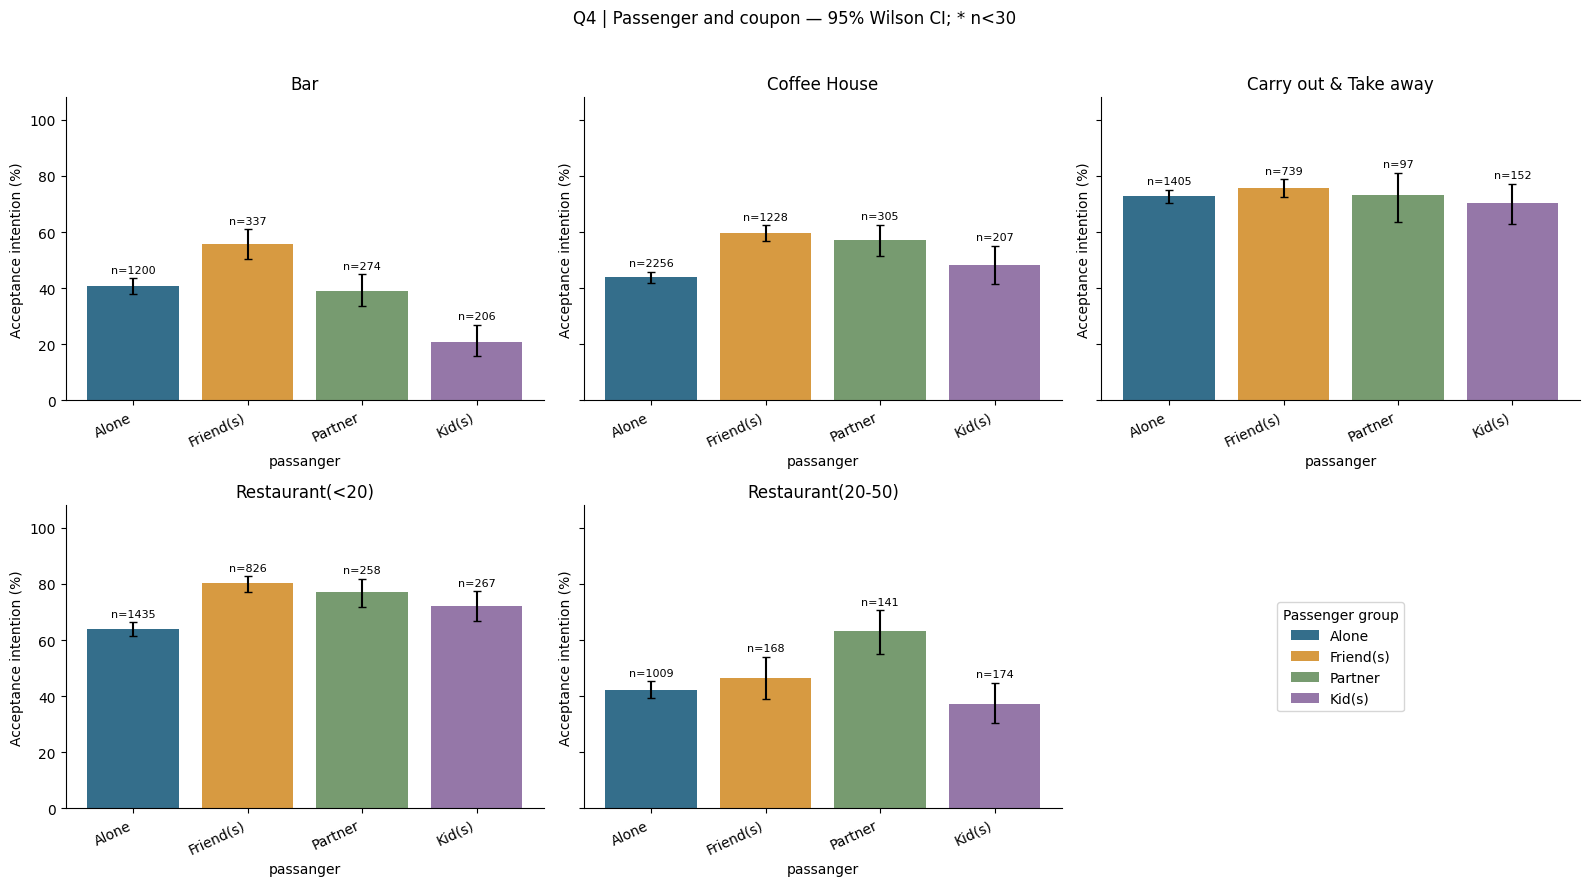

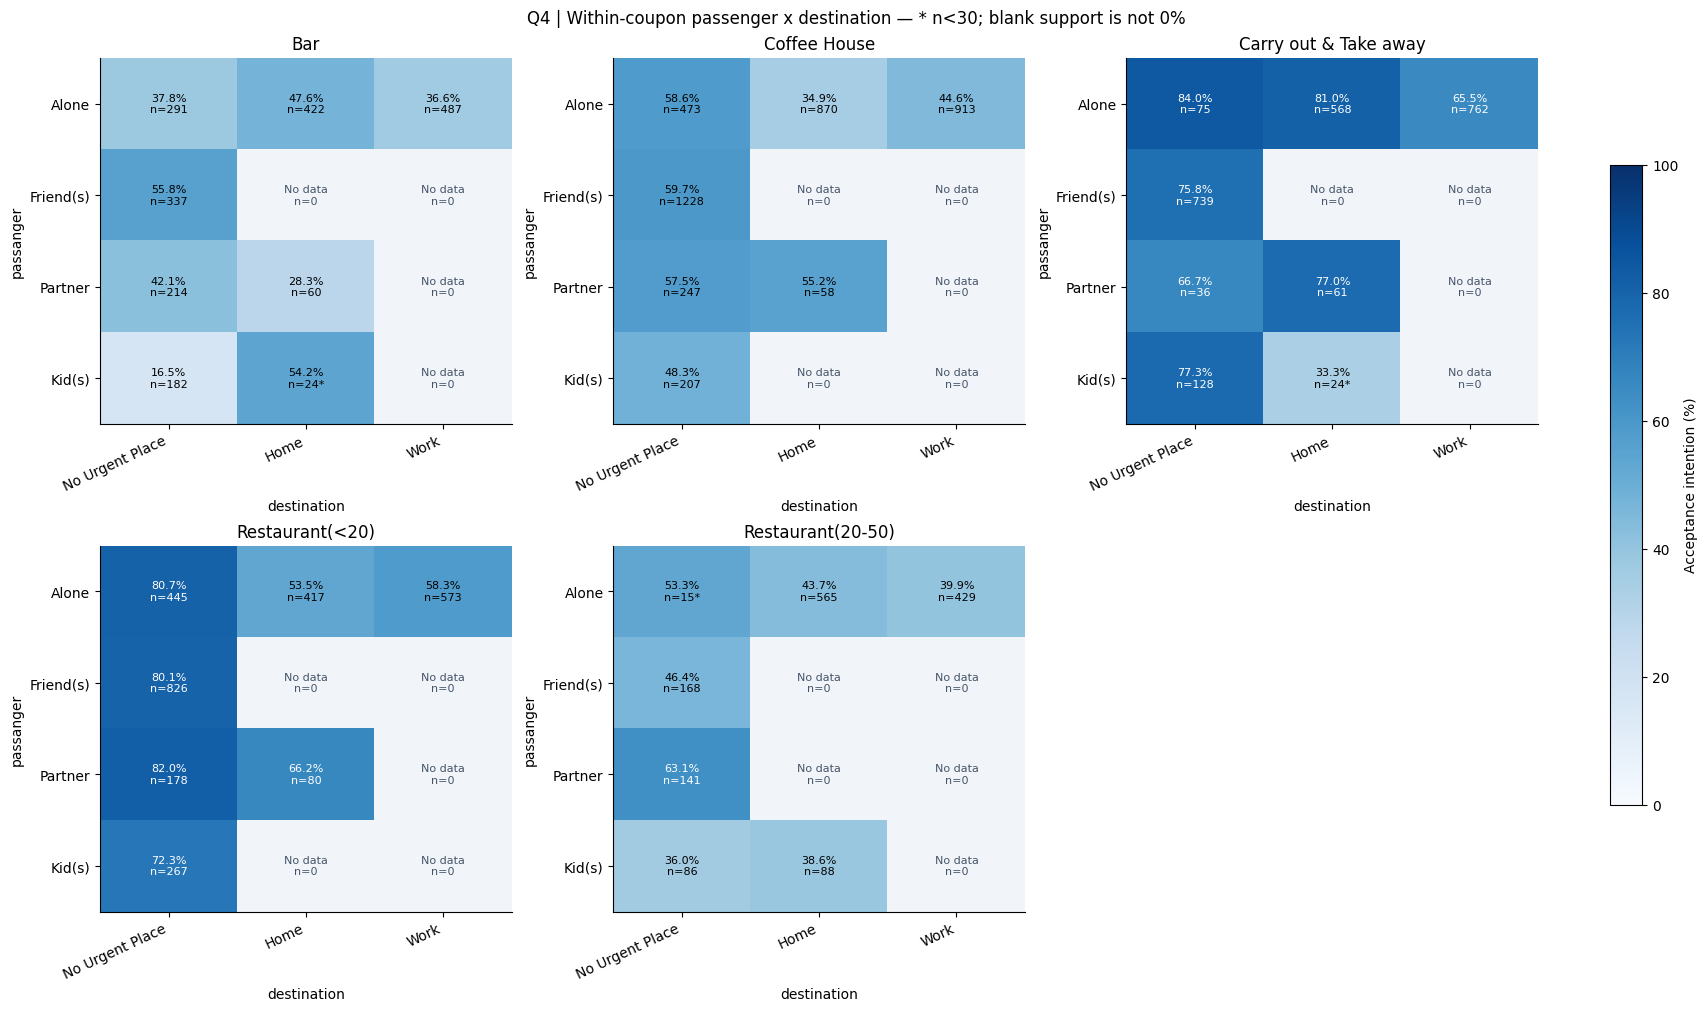

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
colors = ["#346e8b", "#d79a41", "#779b70", "#9577a8"]

for ax, coupon in zip(axes.flat, COUPONS):
    part = (
        coupon_passenger.loc[coupon_passenger["coupon"].eq(coupon)]
        .set_index("passanger")
        .reindex(PASSENGERS)
    )
    for i, passenger in enumerate(PASSENGERS):
        row = part.loc[passenger]
        if pd.isna(row["n"]):
            ax.text(i, 3, "n=0", ha="center", fontsize=8)
            continue

        yerr = np.array([[row["rate"] - row["ci_low"]], [row["ci_high"] - row["rate"]]]) * 100
        ax.bar(i, row["rate"] * 100, color=colors[i], label=passenger)
        ax.errorbar(i, row["rate"] * 100, yerr=yerr, fmt="none", color="black", capsize=3)

        star = "*" if row["n"] < MIN_N else ""
        label_y = min(101, row["ci_high"] * 100 + 2)
        ax.text(i, label_y, f"n={int(row['n'])}{star}", ha="center", fontsize=8)

    ax.set(title=coupon, xlabel="passanger", ylabel="Acceptance intention (%)", ylim=(0, 108))
    ax.set_xticks(range(4), PASSENGERS, rotation=25, ha="right")

axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", title="Passenger group")

fig.suptitle("Q4 | Passenger and coupon — 95% Wilson CI; * n<30")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_figure(fig, ROOT, "q4_passanger_bars")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 10), constrained_layout=True)
for ax, coupon in zip(axes.flat, COUPONS):
    part = joint_rates.loc[joint_rates["coupon"].eq(coupon)]
    img = heatmap_rates(part, "passanger", "destination", PASSENGERS, DESTINATIONS, ax, coupon)

axes.flat[-1].axis("off")
fig.colorbar(img, ax=list(axes.flat), shrink=0.75, label="Acceptance intention (%)")
fig.suptitle("Q4 | Within-coupon passenger x destination — * n<30; blank support is not 0%")
save_figure(fig, ROOT, "q4_destination_heatmaps")
plt.show()

### Q4 kết quả, bất ngờ, ứng dụng và hạn chế — bản nháp
So sánh điểm ước lượng thô với sau phân tầng; không gọi khác biệt là tác động.
Nói rõ khi common support làm thay đổi quần thể. Không có thử nghiệm ngẫu nhiên,
còn khác biệt về người trả lời/sở thích/bối cảnh, nên không xác định nhân quả.

In [9]:
q4_lines = []
for coupon in COUPONS:
    candidates = coupon_passenger.loc[coupon_passenger["coupon"].eq(coupon) & ~coupon_passenger["small_n"]]
    hi = candidates.loc[candidates["rate"].idxmax()]
    lo = candidates.loc[candidates["rate"].idxmin()]
    q4_lines.append(
        f"- {coupon}: trong nhóm n≥30, cao nhất theo điểm ước lượng {hi.passanger} {hi.rate * 100:.2f}% "
        f"(n={int(hi.n)}; Wilson CI [{hi.ci_low * 100:.2f}, {hi.ci_high * 100:.2f}]%), "
        f"thấp nhất {lo.passanger} {lo.rate * 100:.2f}% "
        f"(n={int(lo.n)}; CI [{lo.ci_low * 100:.2f}, {lo.ci_high * 100:.2f}]%). "
        "Không kiểm định mọi thứ hạng."
    )

for row in crude.itertuples():
    q4_lines.append(
        f"- Thô {row.comparison}: {row.rate_a * 100:.2f}% (n={row.n_a}) so với "
        f"{row.rate_b * 100:.2f}% (n={row.n_b}); "
        f"chênh {row.diff_pp:.2f} điểm %, CI [{row.ci_low_pp:.2f}, {row.ci_high_pp:.2f}]."
    )

for row in standardized.loc[standardized["scope"].eq("all coupons")].itertuples():
    q4_lines.append(
        f"- Chuẩn hóa {row.comparison}, {row.adjustment}: chênh {row.diff_pp:.2f} điểm %, "
        f"CI [{row.ci_low_pp:.2f}, {row.ci_high_pp:.2f}]; {row.n_strata_used}/{row.n_strata_total} tầng, "
        f"giữ {row.n_comparison_used}/{row.n_comparison_total} dòng của cặp ({row.coverage * 100:.1f}%). "
        "Đây là quần thể common support."
    )

friend_ok = joint_contrasts.loc[
    joint_contrasts["status"].eq("ok")
    & joint_contrasts["comparison"].eq("Friend(s) - Alone")
]
for row in friend_ok.itertuples():
    q4_lines.append(
        f"- Cùng {row.coupon}, {row.destination}: Friend(s) {row.rate_a * 100:.2f}% (n={row.n_a}) "
        f"so với Alone {row.rate_b * 100:.2f}% (n={row.n_b}), "
        f"chênh {row.diff_pp:.2f} điểm %, CI [{row.ci_low_pp:.2f}, {row.ci_high_pp:.2f}]. "
        "Chiều liên hệ không đồng nhất giữa coupon."
    )

no_support = standardized.loc[
    standardized["status"].eq("no_common_support")
    & standardized["adjustment"].eq("coupon_destination")
]
for row in no_support.itertuples():
    q4_lines.append(
        f"- {row.scope}, {row.comparison}: không có tầng nào đạt cả hai nhóm n≥30; "
        "không tính tỷ lệ/chênh lệch chuẩn hóa. Xem số mẫu ở ha_q4_joint_contrasts.csv."
    )

reversal_rows = []
for row in joint_contrasts.loc[joint_contrasts["status"].eq("ok")].itertuples():
    crude_coupon = coupon_contrasts.loc[
        coupon_contrasts["coupon"].eq(row.coupon)
        & coupon_contrasts["comparison"].eq(row.comparison)
    ].iloc[0]
    is_reversal = bool(np.sign(row.diff_pp) != np.sign(crude_coupon.diff_pp))
    reversal_rows.append({
        "coupon": row.coupon,
        "destination": row.destination,
        "comparison": row.comparison,
        "coupon_diff_pp": crude_coupon.diff_pp,
        "within_destination_diff_pp": row.diff_pp,
        "sign_reversal": is_reversal,
        "n_a": row.n_a,
        "n_b": row.n_b,
        "ci_low_pp": row.ci_low_pp,
        "ci_high_pp": row.ci_high_pp,
    })

reversals = pd.DataFrame(reversal_rows)
display(reversals)
save_table(reversals, ROOT, "q4_sign_reversals")

q4_lines.append(
    f"- Có {int(reversals['sign_reversal'].sum())}/{len(reversals)} tầng đủ n đổi dấu điểm ước lượng "
    "so với cùng coupon chưa phân tầng destination. Đổi dấu không chứng minh khác biệt chắc chắn hay Simpson's paradox; "
    "cần xem CI và quần thể."
)

support = pd.crosstab(q4["passanger"], q4["destination"])
q4_lines.extend([
    (
        f"- Điểm dễ bị bỏ qua: Friend(s) có n={int(support.loc['Friend(s)', 'No Urgent Place'])} ở No Urgent Place, "
        f"n={int(support.loc['Friend(s)', 'Home'])} ở Home và n={int(support.loc['Friend(s)', 'Work'])} ở Work. "
        "Không thể ước lượng so sánh bạn bè/một mình ở mọi mục đích chuyến đi."
    ),
    "- Giả thuyết lý giải: lựa chọn người đi cùng gắn với mục đích/bối cảnh; các thói quen và cấu trúc mẫu cũng có thể liên quan. Không chứng minh cơ chế chỉ bằng phân tầng.",
    "- Ứng dụng có điều kiện: thử nghiệm ưu đãi theo bối cảnh có dữ liệu hỗ trợ; không ngoại suy cho Home/Work nếu cặp so sánh không tồn tại.",
    "- Hạn chế: thiếu người tham gia ID, quan sát phụ thuộc tiềm tàng, tự báo cáo, thiếu common support, nhiều so sánh khám phá; has_children không phải đang đi cùng trẻ. Hà cần tự đánh giá điều gì bất ngờ và diễn giải lại từ bảng gốc.",
])
display(Markdown("\n\n".join(q4_lines)))

,coupon,destination,comparison,coupon_diff_pp,within_destination_diff_pp,sign_reversal,n_a,n_b,ci_low_pp,ci_high_pp
0,Bar,No Urgent Place,Friend(s) - Alone,15.036350,17.985663,False,337,291,10.363323,25.670205
1,Carry out & Take away,No Urgent Place,Friend(s) - Alone,3.037865,-8.221922,True,739,75,-16.647722,0.956247
2,Coffee House,No Urgent Place,Friend(s) - Alone,15.896228,1.128186,False,1228,473,-4.082305,6.333753
3,Restaurant(<20),No Urgent Place,Friend(s) - Alone,16.312526,-0.528879,True,826,445,-5.110360,4.018554
4,Bar,Home,Partner - Alone,-1.698905,-19.296998,False,60,422,-31.213665,-6.461295
5,Bar,No Urgent Place,Partner - Alone,-1.698905,4.255387,True,214,291,-4.445916,13.203303
6,Carry out & Take away,Home,Partner - Alone,0.455663,-3.936735,True,61,568,-15.181251,6.548719
7,Carry out & Take away,No Urgent Place,Partner - Alone,0.455663,-17.333333,True,36,75,-35.222222,0.444444
8,Coffee House,Home,Partner - Alone,13.254854,20.229885,False,58,870,7.011494,33.218391
9,Coffee House,No Urgent Place,Partner - Alone,13.254854,-1.072489,True,247,473,-8.521711,6.570623


- Bar: trong nhóm n≥30, cao nhất theo điểm ước lượng Friend(s) 55.79% (n=337; Wilson CI [50.45, 60.99]%), thấp nhất Kid(s) 20.87% (n=206; CI [15.88, 26.93]%). Không kiểm định mọi thứ hạng.

- Coffee House: trong nhóm n≥30, cao nhất theo điểm ước lượng Friend(s) 59.69% (n=1228; Wilson CI [56.92, 62.40]%), thấp nhất Alone 43.79% (n=2256; CI [41.76, 45.85]%). Không kiểm định mọi thứ hạng.

- Carry out & Take away: trong nhóm n≥30, cao nhất theo điểm ước lượng Friend(s) 75.78% (n=739; Wilson CI [72.56, 78.73]%), thấp nhất Kid(s) 70.39% (n=152; CI [62.71, 77.08]%). Không kiểm định mọi thứ hạng.

- Restaurant(<20): trong nhóm n≥30, cao nhất theo điểm ước lượng Friend(s) 80.15% (n=826; Wilson CI [77.29, 82.72]%), thấp nhất Alone 63.83% (n=1435; CI [61.31, 66.28]%). Không kiểm định mọi thứ hạng.

- Restaurant(20-50): trong nhóm n≥30, cao nhất theo điểm ước lượng Partner 63.12% (n=141; Wilson CI [54.91, 70.64]%), thấp nhất Kid(s) 37.36% (n=174; CI [30.51, 44.74]%). Không kiểm định mọi thứ hạng.

- Thô Friend(s) - Alone: 67.34% (n=3298) so với 52.58% (n=7305); chênh 14.76 điểm %, CI [12.81, 16.70].

- Thô Partner - Alone: 59.53% (n=1075) so với 52.58% (n=7305); chênh 6.95 điểm %, CI [3.78, 10.01].

- Chuẩn hóa Friend(s) - Alone, coupon_destination: chênh 1.33 điểm %, CI [-1.78, 4.48]; 4/15 tầng, giữ 4414/10603 dòng của cặp (41.6%). Đây là quần thể common support.

- Chuẩn hóa Friend(s) - Alone, coupon_destination_children: chênh 2.15 điểm %, CI [-0.87, 5.27]; 7/30 tầng, giữ 4082/10603 dòng của cặp (38.5%). Đây là quần thể common support.

- Chuẩn hóa Partner - Alone, coupon_destination: chênh 3.03 điểm %, CI [-1.11, 7.08]; 8/15 tầng, giữ 4495/8380 dòng của cặp (53.6%). Đây là quần thể common support.

- Chuẩn hóa Partner - Alone, coupon_destination_children: chênh 2.31 điểm %, CI [-2.26, 6.72]; 8/30 tầng, giữ 2844/8380 dòng của cặp (33.9%). Đây là quần thể common support.

- Cùng Bar, No Urgent Place: Friend(s) 55.79% (n=337) so với Alone 37.80% (n=291), chênh 17.99 điểm %, CI [10.36, 25.67]. Chiều liên hệ không đồng nhất giữa coupon.

- Cùng Carry out & Take away, No Urgent Place: Friend(s) 75.78% (n=739) so với Alone 84.00% (n=75), chênh -8.22 điểm %, CI [-16.65, 0.96]. Chiều liên hệ không đồng nhất giữa coupon.

- Cùng Coffee House, No Urgent Place: Friend(s) 59.69% (n=1228) so với Alone 58.56% (n=473), chênh 1.13 điểm %, CI [-4.08, 6.33]. Chiều liên hệ không đồng nhất giữa coupon.

- Cùng Restaurant(<20), No Urgent Place: Friend(s) 80.15% (n=826) so với Alone 80.67% (n=445), chênh -0.53 điểm %, CI [-5.11, 4.02]. Chiều liên hệ không đồng nhất giữa coupon.

- Restaurant(20-50), Friend(s) - Alone: không có tầng nào đạt cả hai nhóm n≥30; không tính tỷ lệ/chênh lệch chuẩn hóa. Xem số mẫu ở ha_q4_joint_contrasts.csv.

- Restaurant(20-50), Partner - Alone: không có tầng nào đạt cả hai nhóm n≥30; không tính tỷ lệ/chênh lệch chuẩn hóa. Xem số mẫu ở ha_q4_joint_contrasts.csv.

- Có 6/12 tầng đủ n đổi dấu điểm ước lượng so với cùng coupon chưa phân tầng destination. Đổi dấu không chứng minh khác biệt chắc chắn hay Simpson's paradox; cần xem CI và quần thể.

- Điểm dễ bị bỏ qua: Friend(s) có n=3298 ở No Urgent Place, n=0 ở Home và n=0 ở Work. Không thể ước lượng so sánh bạn bè/một mình ở mọi mục đích chuyến đi.

- Giả thuyết lý giải: lựa chọn người đi cùng gắn với mục đích/bối cảnh; các thói quen và cấu trúc mẫu cũng có thể liên quan. Không chứng minh cơ chế chỉ bằng phân tầng.

- Ứng dụng có điều kiện: thử nghiệm ưu đãi theo bối cảnh có dữ liệu hỗ trợ; không ngoại suy cho Home/Work nếu cặp so sánh không tồn tại.

- Hạn chế: thiếu người tham gia ID, quan sát phụ thuộc tiềm tàng, tự báo cáo, thiếu common support, nhiều so sánh khám phá; has_children không phải đang đi cùng trẻ. Hà cần tự đánh giá điều gì bất ngờ và diễn giải lại từ bảng gốc.

## Bàn giao số liệu, audit và kiểm tra cuối
Bản nháp có số liệu để học/đối chiếu; không tự đánh dấu Hà đã review, viết
reflection, hay hoàn tất bài nộp. Nguồn: [UCI #603](https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation),
DOI 10.24432/C5GS4P, CC BY 4.0. Phương pháp Wilson: tài liệu SciPy được dẫn ở protocol.

In [10]:
audit_table = pd.DataFrame(audit)
display(audit_table)
save_table(audit_table, ROOT, "q3_q4_row_audit")

assert frequency_rates["n"].sum() == len(df)
assert coupon_passenger["n"].sum() == len(df)
assert joint_rates["n"].sum() == len(df)
assert primary["n_a"].sum() + primary["n_b"].sum() == q3["matched_frequency"].notna().sum()
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_sha

report = (
    "# Hà — Q3/Q4: bản nháp AI hỗ trợ\n\n"
    "Số liệu tự sinh từ CSV thật. Chưa xác nhận Hà tự thực hiện/diễn giải; xem LLM_USAGE.md.\n\n"
    "## Q3\n\n"
    + "\n\n".join(q3_lines)
    + "\n\n## Q4\n\n"
    + "\n\n".join(q4_lines)
    + "\n\n## Bằng chứng\n\n"
    "- Q3: reports/tables/ha_q3_primary_contrasts.csv, ha_q3_sensitivity.csv, ha_q3_dedup_contrasts.csv.\n"
    "- Q4: reports/tables/ha_q4_*rates.csv, ha_q4_*contrasts.csv, ha_q4_sign_reversals.csv.\n"
    "- Row audit: reports/tables/ha_q3_q4_row_audit.csv.\n"
    "- Hình: reports/figures/ha_q3_frequency_bars.png, ha_q3_frequency_heatmap.png, ha_q4_passanger_bars.png, ha_q4_destination_heatmaps.png.\n"
    "- Nguồn: UCI Dataset 603, DOI https://doi.org/10.24432/C5GS4P, CC BY 4.0.\n"
    "- CI giả định dòng độc lập; bootstrap percentile 10.000 lượt; seed 17104; MIN_N=30.\n"
)
(ROOT / "reports/ha_findings.md").write_text(report, encoding="utf-8")
print("Saved reports/ha_findings.md and row audit. Raw unchanged.")

,action,n_before,n_after,rows_removed,reason
0,Q3 mapping and frequent_user,12684,12684,0,"Add variables, no row removal; NaN remains unk..."
1,Q3 at_least_1 / complete_case,12684,12520,164,"Exclude only missing matched habit, not all mi..."
2,Q3 at_least_1 / within_coupon_mode,12684,12684,0,Descriptive sensitivity only; fill matched hab...
3,Q3 at_least_4 / complete_case,12684,12520,164,"Exclude only missing matched habit, not all mi..."
4,Q3 at_least_4 / within_coupon_mode,12684,12684,0,Descriptive sensitivity only; fill matched hab...
5,Q3 dedup sensitivity,12684,12610,74,Sensitivity only; not claiming duplicate surve...
6,Q3 dedup matched complete cases,12610,12447,163,Exclude missing matched habit only
7,Q4 complete required fields,12684,12684,0,No missing required Q4 fields; no removal
8,Q4 select Friend(s) vs Alone,12684,10603,2081,Other passenger groups outside preselected com...
9,Q4 common support Friend(s) / coupon_destination,10603,4414,6189,Retain strata with both groups n>=30; support ...


Saved reports/ha_findings.md and row audit. Raw unchanged.
